In [1]:
# ÉTAPE 1 : Importer les bibliothèques et créer les données
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("ÉTAPE 1 : Préparation des données")
print("-" * 40)

# Créer le DataFrame de base
data = {
    'City': ['Alger', 'Annaba', 'Oran', 'Alger', 'Oran', 'Annaba', 'Alger', 'Oran'],
    'Department': ['Cardiology', 'Neurology', 'Orthopedics', 'Cardiology', 
                   'Neurology', 'Orthopedics', 'Cardiology', 'Neurology'],
    'Age': [45, 60, 30, 50, 40, 70, 35, 55],
    'DaysAdmitted': [5, 8, 3, 7, 4, 6, 2, 9],
    'DailyFee': [200, 300, 150, 220, 280, 160, 210, 290],
    'Satisfaction': [4.5, 3.8, 4.2, 4.0, 4.1, 3.5, 4.7, 3.9],
    'Readmitted': [0, 1, 0, 0, 1, 1, 0, 1]
}

df = pd.DataFrame(data)
print("✓ DataFrame créé")
print(f"Nombre de patients : {len(df)}")
print(f"Colonnes : {list(df.columns)}")

# Calculer les colonnes supplémentaires
df['TotalCost'] = df['DaysAdmitted'] * df['DailyFee']
print("✓ Colonne TotalCost calculée (jours × coût journalier)")

df['RiskScore'] = (df['DaysAdmitted'] * 0.4) + (df['Age'] * 0.3) + ((100 - df['Satisfaction'] * 10) * 0.3)
print("✓ Colonne RiskScore calculée")

df['RiskCategory'] = pd.cut(df['RiskScore'], bins=[0, 39.9, 60, 100], labels=['Low', 'Medium', 'High'])
print("✓ Colonne RiskCategory créée (Low/Medium/High)")

print("\nAperçu des données :")
print(df.head())
print()

ÉTAPE 1 : Préparation des données
----------------------------------------
✓ DataFrame créé
Nombre de patients : 8
Colonnes : ['City', 'Department', 'Age', 'DaysAdmitted', 'DailyFee', 'Satisfaction', 'Readmitted']
✓ Colonne TotalCost calculée (jours × coût journalier)
✓ Colonne RiskScore calculée
✓ Colonne RiskCategory créée (Low/Medium/High)

Aperçu des données :
     City   Department  Age  DaysAdmitted  DailyFee  Satisfaction  Readmitted  \
0   Alger   Cardiology   45             5       200           4.5           0   
1  Annaba    Neurology   60             8       300           3.8           1   
2    Oran  Orthopedics   30             3       150           4.2           0   
3   Alger   Cardiology   50             7       220           4.0           0   
4    Oran    Neurology   40             4       280           4.1           1   

   TotalCost  RiskScore RiskCategory  
0       1000       32.0          Low  
1       2400       39.8          Low  
2        450       27.6      


ÉTAPE 2 : Matplotlib - Graphique à barres (coût par ville)
----------------------------------------
1. Coût total par ville :
   Alger : 2960 DA
   Annaba : 3360 DA
   Oran : 4180 DA


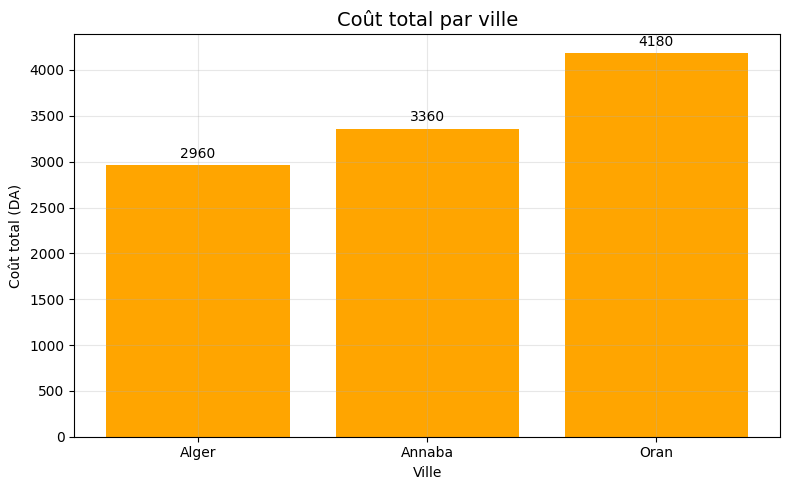

✓ Graphique affiché : Barres orange avec valeurs annotées



In [7]:
print("\nÉTAPE 2 : Matplotlib - Graphique à barres (coût par ville)")
print("-" * 40)

# Étape 2.1 : Calculer le coût total par ville
city_costs = df.groupby('City')['TotalCost'].sum()
print("1. Coût total par ville :")
for city, cost in city_costs.items():
    print(f"   {city} : {cost} DA")

# Étape 2.2 : Créer le graphique
plt.figure(figsize=(8, 5))  # Créer une nouvelle figure

# Créer les barres
bars = plt.bar(city_costs.index, city_costs.values, color='orange')

# Ajouter le titre et les labels
plt.title('Coût total par ville', fontsize=14)
plt.xlabel('Ville')
plt.ylabel('Coût total (DA)')

# Étape 2.3 : Ajouter les valeurs sur les barres
for bar in bars:
    height = bar.get_height()  # Hauteur de la barre
    plt.text(bar.get_x() + bar.get_width()/2,  # Position x (centre de la barre)
             height + 50,                      # Position y (juste au-dessus)
             f'{int(height)}',                 # Texte (valeur arrondie)
             ha='center',                      # Alignement horizontal au centre
             va='bottom')                      # Alignement vertical en bas

plt.grid(True, alpha=0.3)  # Ajouter une grille
plt.tight_layout()         # Ajuster l'espacement
plt.show()                 # Afficher le graphique

print("✓ Graphique affiché : Barres orange avec valeurs annotées")
print()


ÉTAPE 3 : Matplotlib - Histogramme de satisfaction
----------------------------------------
1. Moyenne : 4.09
2. Médiane : 4.05


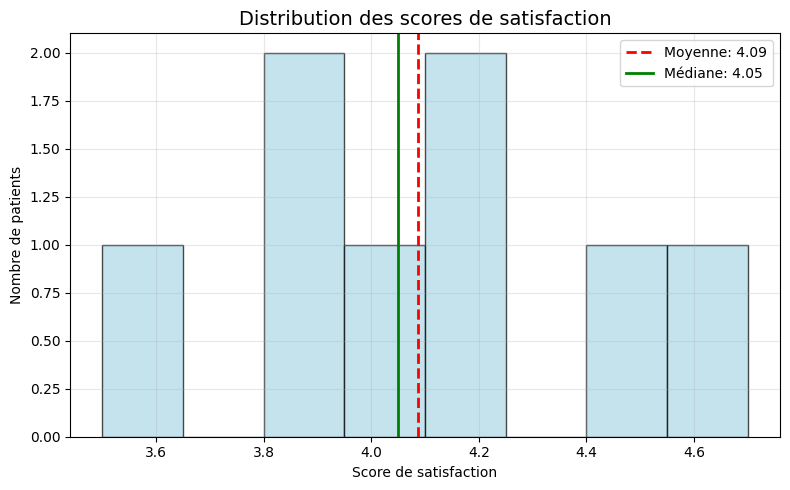

✓ Histogramme affiché :
   - Barres bleues avec bordure noire
   - Ligne rouge pointillée : moyenne
   - Ligne verte pleine : médiane



In [16]:
print("\nÉTAPE 3 : Matplotlib - Histogramme de satisfaction")
print("-" * 40)

plt.figure(figsize=(8, 5))

# Étape 3.1 : Créer l'histogramme
n, bins, patches = plt.hist(df['Satisfaction'], 
                           bins=8,                    # 8 intervalles
                           color='lightblue',         # Couleur des barres
                           edgecolor='black',         # Bordure noire
                           alpha=0.7)                 # Transparence

# Étape 3.2 : Calculer moyenne et médiane
mean_val = df['Satisfaction'].mean()
median_val = df['Satisfaction'].median()
print(f"1. Moyenne : {mean_val:.2f}")
print(f"2. Médiane : {median_val:.2f}")

# Étape 3.3 : Ajouter les lignes de référence
plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Moyenne: {mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Médiane: {median_val:.2f}')

# Étape 3.4 : Configuration finale
plt.title('Distribution des scores de satisfaction', fontsize=14)
plt.xlabel('Score de satisfaction')
plt.ylabel('Nombre de patients')
plt.legend()  # Afficher la légende
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Histogramme affiché :")
print("   - Barres bleues avec bordure noire")
print("   - Ligne rouge pointillée : moyenne")
print("   - Ligne verte pleine : médiane")
print()


ÉTAPE 4 : Matplotlib - Nuage de points
----------------------------------------


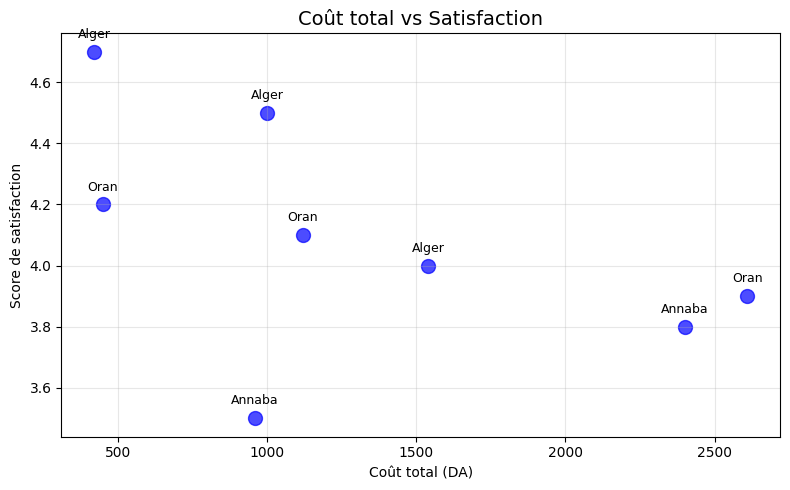

✓ Nuage de points affiché :
   - Points bleus avec noms des villes
   - Chaque point représente un patient
   - Annotations au-dessus des points



In [19]:
print("\nÉTAPE 4 : Matplotlib - Nuage de points")
print("-" * 40)

plt.figure(figsize=(8, 5))

# Étape 4.1 : Créer le nuage de points
plt.scatter(df['TotalCost'],    # Valeurs en x
            df['Satisfaction'], # Valeurs en y
            s=100,              # Taille des points
            c='blue',           # Couleur des points
            marker='o',         # Forme des points (cercle)
            alpha=0.7)          # Transparence

# Étape 4.2 : Ajouter les annotations (noms des villes)
for i, row in df.iterrows():
    plt.annotate(row['City'],                    # Texte (nom de la ville)
                 (row['TotalCost'], row['Satisfaction']),  # Position
                 textcoords="offset points",     # Type de coordonnées
                 xytext=(0, 10),                 # Décalage (10 pixels vers le haut)
                 ha='center',                    # Alignement horizontal au centre
                 fontsize=9)

# Étape 4.3 : Configuration
plt.title('Coût total vs Satisfaction', fontsize=14)
plt.xlabel('Coût total (DA)')
plt.ylabel('Score de satisfaction')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Nuage de points affiché :")
print("   - Points bleus avec noms des villes")
print("   - Chaque point représente un patient")
print("   - Annotations au-dessus des points")
print()


ÉTAPE 5 : Matplotlib - Sous-graphiques
----------------------------------------


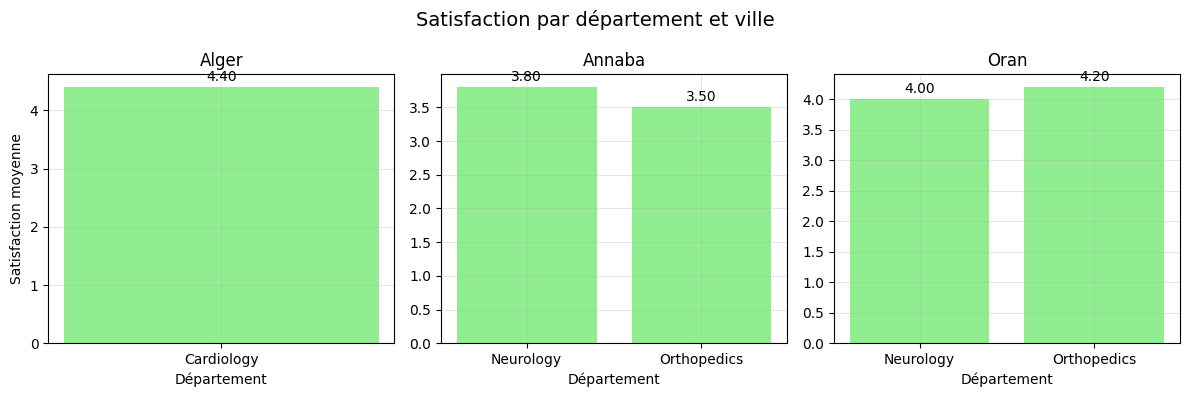

✓ Sous-graphiques affichés :
   - 3 graphiques (un par ville)
   - Satisfaction moyenne par département
   - Mêmes échelles pour comparaison



In [20]:
print("\nÉTAPE 5 : Matplotlib - Sous-graphiques")
print("-" * 40)

# Étape 5.1 : Créer la grille de sous-graphiques
fig, axes = plt.subplots(1, 3, figsize=(12, 4))  # 1 ligne, 3 colonnes
fig.suptitle('Satisfaction par département et ville', fontsize=14)

# Liste des villes
cities = df['City'].unique()

# Étape 5.2 : Pour chaque ville, créer un graphique
for idx, city in enumerate(cities):
    ax = axes[idx]  # Sélectionner le sous-graphique courant
    
    # Filtrer les données pour cette ville
    city_data = df[df['City'] == city]
    
    # Calculer la satisfaction moyenne par département
    dept_means = city_data.groupby('Department')['Satisfaction'].mean()
    
    # Créer les barres
    bars = ax.bar(dept_means.index, dept_means.values, color='lightgreen')
    
    # Configurer le sous-graphique
    ax.set_title(city)
    ax.set_xlabel('Département')
    if idx == 0:  # Seulement pour le premier graphique
        ax.set_ylabel('Satisfaction moyenne')
    
    # Ajouter les valeurs sur les barres
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.05,
                f'{height:.2f}', ha='center', va='bottom')
    
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Sous-graphiques affichés :")
print("   - 3 graphiques (un par ville)")
print("   - Satisfaction moyenne par département")
print("   - Mêmes échelles pour comparaison")
print()


ÉTAPE 6 : Seaborn - Performance économique et satisfaction
----------------------------------------


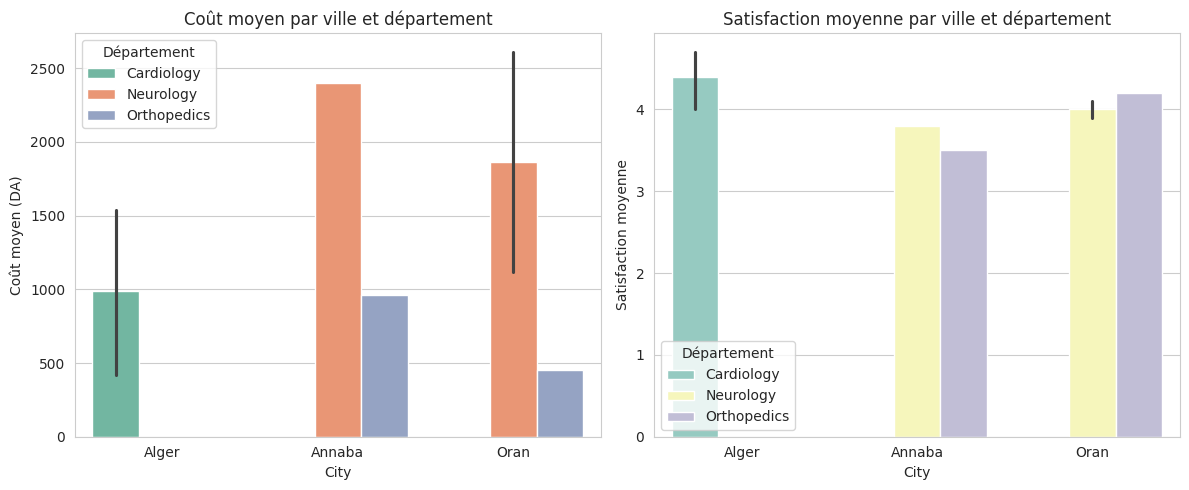

✓ Graphiques Seaborn affichés :
   - Graphique gauche : Coût moyen
   - Graphique droit : Satisfaction moyenne
   - Couleurs différentes par département (hue)



In [21]:
print("\nÉTAPE 6 : Seaborn - Performance économique et satisfaction")
print("-" * 40)

# Étape 6.1 : Configuration de Seaborn
sns.set_style("whitegrid")  # Style avec grille

# Étape 6.2 : Créer une figure avec 2 sous-graphiques
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Graphique 1 : Coût moyen
sns.barplot(data=df, x='City', y='TotalCost', hue='Department', 
            ax=ax1, palette='Set2')
ax1.set_title('Coût moyen par ville et département')
ax1.set_ylabel('Coût moyen (DA)')
ax1.legend(title='Département')

# Graphique 2 : Satisfaction moyenne
sns.barplot(data=df, x='City', y='Satisfaction', hue='Department',
            ax=ax2, palette='Set3')
ax2.set_title('Satisfaction moyenne par ville et département')
ax2.set_ylabel('Satisfaction moyenne')
ax2.legend(title='Département')

plt.tight_layout()
plt.show()

print("✓ Graphiques Seaborn affichés :")
print("   - Graphique gauche : Coût moyen")
print("   - Graphique droit : Satisfaction moyenne")
print("   - Couleurs différentes par département (hue)")
print()


ÉTAPE 7 : Seaborn - Distribution du RiskScore
----------------------------------------


/tmp/ipykernel_6878/843588150.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='City', y='RiskScore',
/tmp/ipykernel_6878/843588150.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='City', y='RiskScore',


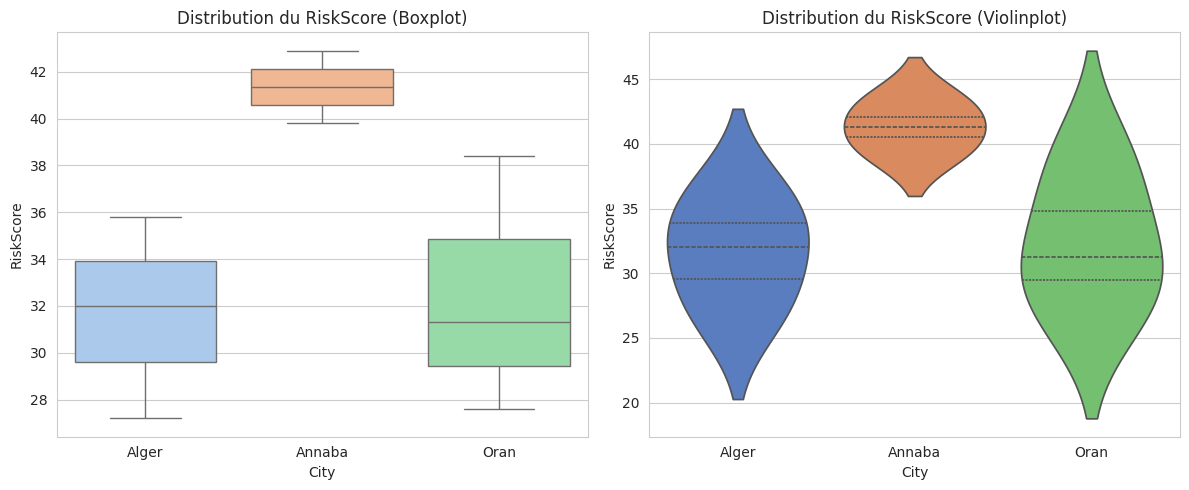

✓ Deux visualisations de distribution :
1. Boxplot :
   - Montre médiane, quartiles et outliers
   - Simple et clair
2. Violinplot :
   - Montre la densité de distribution
   - Plus détaillé mais plus complexe



In [22]:
print("\nÉTAPE 7 : Seaborn - Distribution du RiskScore")
print("-" * 40)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Étape 7.1 : Boxplot
sns.boxplot(data=df, x='City', y='RiskScore', 
            palette='pastel', ax=ax1)
ax1.set_title('Distribution du RiskScore (Boxplot)')
ax1.set_ylabel('RiskScore')

# Étape 7.2 : Violinplot
sns.violinplot(data=df, x='City', y='RiskScore',
               palette='muted', inner='quartile', ax=ax2)
ax2.set_title('Distribution du RiskScore (Violinplot)')
ax2.set_ylabel('RiskScore')

plt.tight_layout()
plt.show()

print("✓ Deux visualisations de distribution :")
print("1. Boxplot :")
print("   - Montre médiane, quartiles et outliers")
print("   - Simple et clair")
print("2. Violinplot :")
print("   - Montre la densité de distribution")
print("   - Plus détaillé mais plus complexe")
print()


ÉTAPE 8 : Seaborn - Matrice de corrélation
----------------------------------------
Matrice de corrélation calculée :
               Age  DaysAdmitted  DailyFee  Satisfaction  TotalCost  RiskScore
Age           1.00          0.75      0.20         -0.81       0.58       0.98
DaysAdmitted  0.75          1.00      0.55         -0.68       0.93       0.83
DailyFee      0.20          0.55      1.00         -0.14       0.79       0.26
Satisfaction -0.81         -0.68     -0.14          1.00      -0.52      -0.88
TotalCost     0.58          0.93      0.79         -0.52       1.00       0.66
RiskScore     0.98          0.83      0.26         -0.88       0.66       1.00


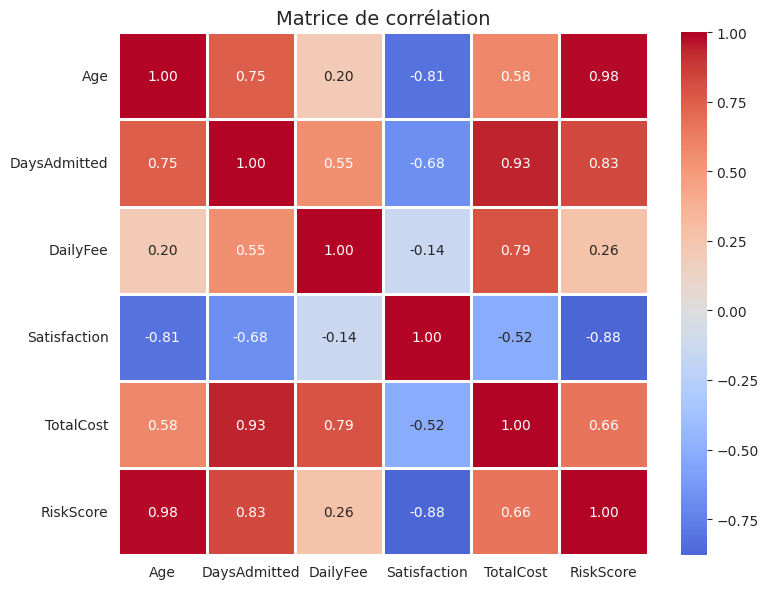

✓ Heatmap affichée :
   - Rouge : corrélation positive forte
   - Bleu : corrélation négative forte
   - Blanc : corrélation faible



In [23]:
print("\nÉTAPE 8 : Seaborn - Matrice de corrélation")
print("-" * 40)

# Étape 8.1 : Sélectionner les colonnes numériques
numeric_cols = ['Age', 'DaysAdmitted', 'DailyFee', 'Satisfaction', 'TotalCost', 'RiskScore']
corr_data = df[numeric_cols]

# Étape 8.2 : Calculer la matrice de corrélation
corr_matrix = corr_data.corr()
print("Matrice de corrélation calculée :")
print(corr_matrix.round(2))

# Étape 8.3 : Créer la heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, 
            annot=True,       # Afficher les valeurs
            cmap='coolwarm',  # Palette de couleurs
            center=0,         # Centre à 0 (corrélation nulle)
            fmt='.2f',        # Format à 2 décimales
            linewidths=1)     # Largeur des lignes

plt.title('Matrice de corrélation', fontsize=14)
plt.tight_layout()
plt.show()

print("✓ Heatmap affichée :")
print("   - Rouge : corrélation positive forte")
print("   - Bleu : corrélation négative forte")
print("   - Blanc : corrélation faible")
print()


ÉTAPE 9 : Seaborn - Pairplot (relations multiples)
----------------------------------------


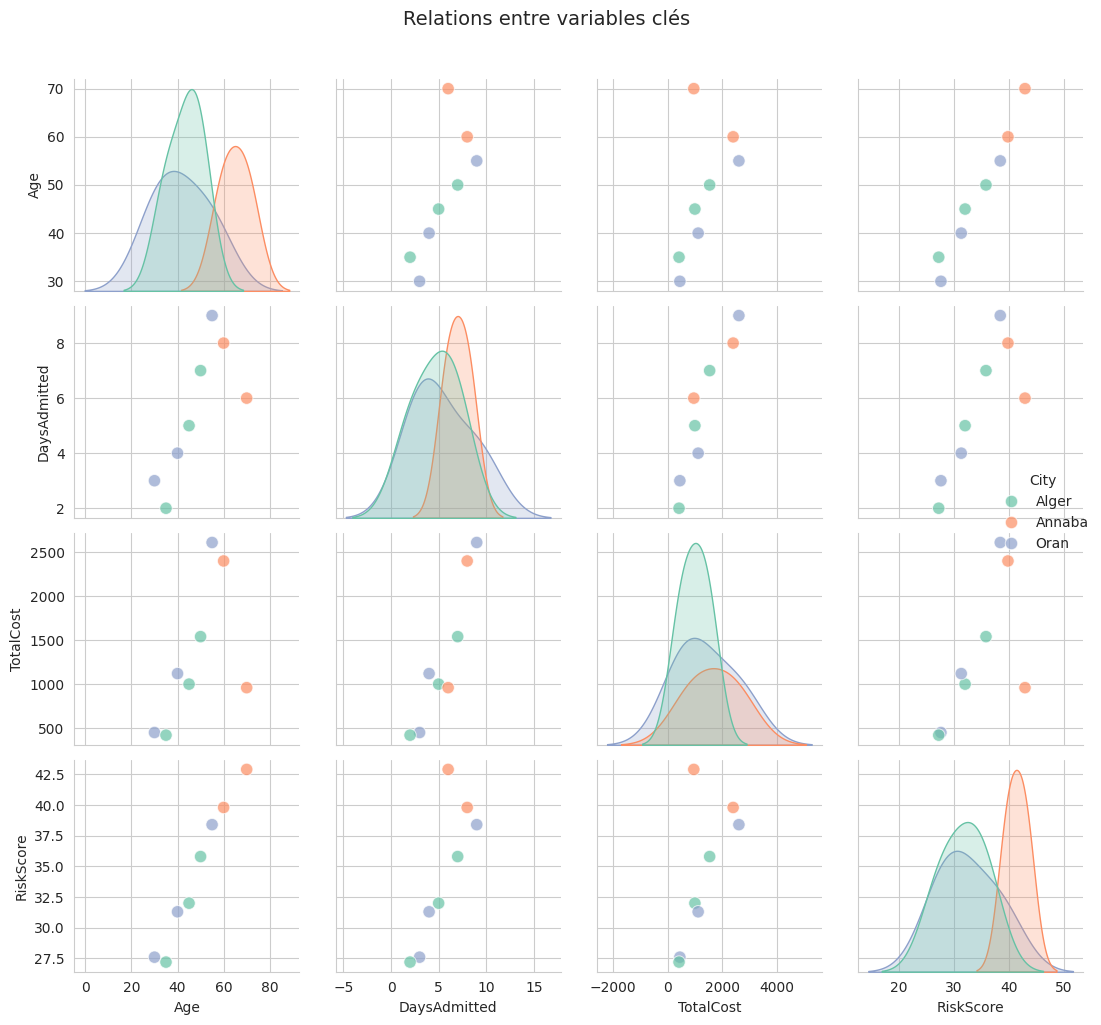

✓ Pairplot affiché :
   - Matrice de scatter plots
   - Diagonale : distribution de chaque variable
   - Couleurs différentes par ville
   - Montre toutes les relations possibles



In [24]:
print("\nÉTAPE 9 : Seaborn - Pairplot (relations multiples)")
print("-" * 40)

# Étape 9.1 : Sélectionner les variables d'intérêt
pairplot_data = df[['Age', 'DaysAdmitted', 'TotalCost', 'RiskScore', 'City']]

# Étape 9.2 : Créer le pairplot
pairplot = sns.pairplot(pairplot_data, 
                        hue='City',       # Couleur par ville
                        palette='Set2',   # Palette de couleurs
                        diag_kind='kde',  # Histogramme lissé en diagonale
                        plot_kws={'alpha': 0.7, 's': 80})  # Paramètres des points

pairplot.fig.suptitle('Relations entre variables clés', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

print("✓ Pairplot affiché :")
print("   - Matrice de scatter plots")
print("   - Diagonale : distribution de chaque variable")
print("   - Couleurs différentes par ville")
print("   - Montre toutes les relations possibles")
print()


ÉTAPE 10 : Seaborn - Tableau de bord complet
----------------------------------------


/tmp/ipykernel_6878/303886263.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='City', y='Satisfaction', ax=axes[0, 0], palette='viridis')
/tmp/ipykernel_6878/303886263.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='RiskCategory', y='RiskScore', ax=axes[0, 1], palette='Set2')


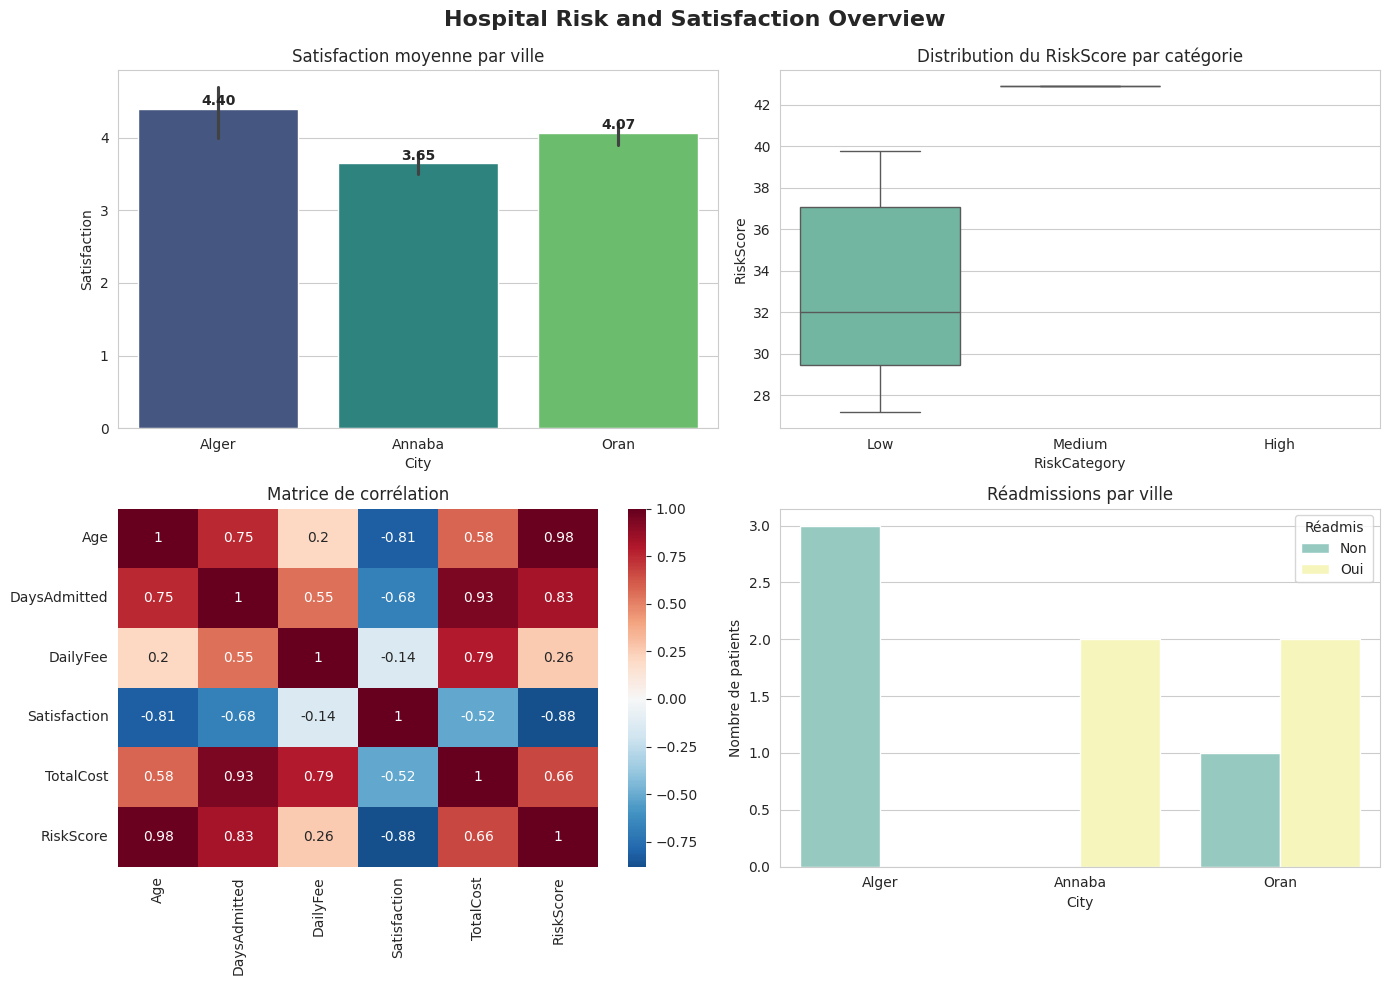

✓ Tableau de bord complet affiché :
   [1] Satisfaction par ville
   [2] RiskScore par catégorie
   [3] Matrice de corrélation
   [4] Réadmissions par ville

✅ Toutes les visualisations sont terminées!


In [25]:
print("\nÉTAPE 10 : Seaborn - Tableau de bord complet")
print("-" * 40)

# Étape 10.1 : Créer la grille 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Hospital Risk and Satisfaction Overview', fontsize=16, fontweight='bold')

# Étape 10.2 : Graphique 1 (en haut à gauche) - Satisfaction par ville
sns.barplot(data=df, x='City', y='Satisfaction', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Satisfaction moyenne par ville')
axes[0, 0].set_ylabel('Satisfaction')

# Ajouter les valeurs sur les barres
for i, bar in enumerate(axes[0, 0].patches):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                   f'{bar.get_height():.2f}', ha='center', fontweight='bold')

# Étape 10.3 : Graphique 2 (en haut à droite) - RiskScore par catégorie
sns.boxplot(data=df, x='RiskCategory', y='RiskScore', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Distribution du RiskScore par catégorie')
axes[0, 1].set_ylabel('RiskScore')

# Étape 10.4 : Graphique 3 (en bas à gauche) - Matrice de corrélation
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, ax=axes[1, 0])
axes[1, 0].set_title('Matrice de corrélation')

# Étape 10.5 : Graphique 4 (en bas à droite) - Réadmissions
df['Readmitted_Text'] = df['Readmitted'].map({0: 'Non', 1: 'Oui'})
sns.countplot(data=df, x='City', hue='Readmitted_Text', ax=axes[1, 1], palette='Set3')
axes[1, 1].set_title('Réadmissions par ville')
axes[1, 1].set_ylabel('Nombre de patients')
axes[1, 1].legend(title='Réadmis')

plt.tight_layout()
plt.subplots_adjust(top=0.92)  # Ajuster pour le titre principal
plt.show()

print("✓ Tableau de bord complet affiché :")
print("   [1] Satisfaction par ville")
print("   [2] RiskScore par catégorie")
print("   [3] Matrice de corrélation")
print("   [4] Réadmissions par ville")
print("\n✅ Toutes les visualisations sont terminées!")